# 01 - Data exploration

Quick look at the 10-word subset of **Google Speech Commands v2** before modelling:
class balance, clip durations, what a waveform / log-mel spectrogram / MFCC looks like,
and what the background noises sound like at different SNRs.

Run `python -m src.data` first (download + split).

In [1]:
import os, sys
os.chdir('..') if os.path.basename(os.getcwd()) == 'notebooks' else None
sys.path.insert(0, os.getcwd())

import numpy as np, pandas as pd, matplotlib.pyplot as plt, librosa, librosa.display
import soundfile as sf
from src.data import WORDS, load_split
from src.features import (DATASET_DIR, SR, HOP, preprocess, load_audio, log_mel,
                          load_background_noises, random_noise_segment, add_noise_snr)
plt.rcParams['figure.dpi'] = 110

## 1. Split sizes and class balance

In [2]:
splits = {s: pd.DataFrame(load_split(s)) for s in ('train', 'val', 'test')}
counts = pd.DataFrame({s: df['label'].value_counts() for s, df in splits.items()}).loc[WORDS]
counts.loc['TOTAL'] = counts.sum()
for s, df in splits.items():
    print(f"{s:5}: {len(df):6d} clips, {df['speaker'].nunique():5d} speakers")
counts

train:  30769 clips,  2008 speakers
val  :   3703 clips,   245 speakers
test :   4074 clips,   239 speakers


,train,val,test
label,,,
yes,3228,397,419
no,3130,406,405
up,2948,350,425
down,3134,377,406
left,3037,352,412
right,3019,363,396
on,3086,363,396
off,2970,373,402
stop,3111,350,411


In [3]:
tr, va, te = (set(splits[s]['speaker']) for s in ('train', 'val', 'test'))
print('speakers shared train/val:', len(tr & va), '| train/test:', len(tr & te), '| val/test:', len(va & te))

speakers shared train/val: 0 | train/test: 0 | val/test: 0


The classes are roughly balanced (≈3 000 training clips each) and no speaker is shared between splits, so test scores measure generalisation to **new voices**.

## 2. Clip durations

Most clips last exactly 1 s, but some are shorter: they are padded with zeros.

8.0 % of clips are shorter than 1 s; min 0.42 s


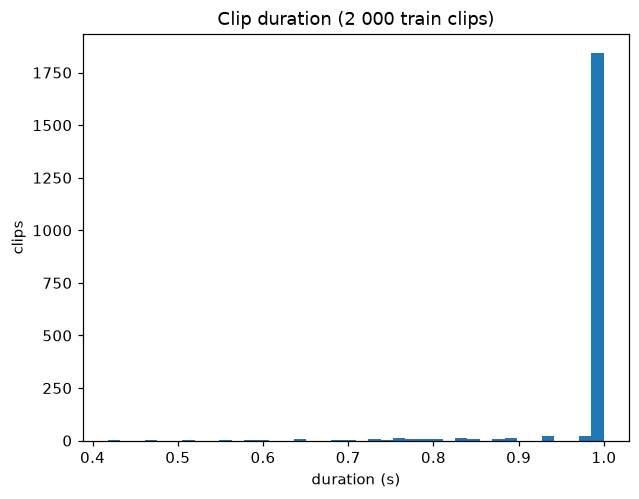

In [4]:
rng = np.random.default_rng(0)
sample = splits['train'].sample(2000, random_state=0)
durations = np.array([sf.info(DATASET_DIR / p).duration for p in sample['path']])
print(f'{(durations < 0.999).mean()*100:.1f} % of clips are shorter than 1 s; min {durations.min():.2f} s')
plt.hist(durations, bins=40); plt.xlabel('duration (s)'); plt.ylabel('clips'); plt.title('Clip duration (2 000 train clips)'); plt.show()

## 3. One clip, three representations

* **waveform**: amplitude over time (16 000 samples)
* **log-mel spectrogram**: energy per frequency band (mel scale ≈ human pitch perception) every 10 ms — the CNN input
* **MFCC**: a compressed (13 coefficients) description of the spectral envelope — the classical features

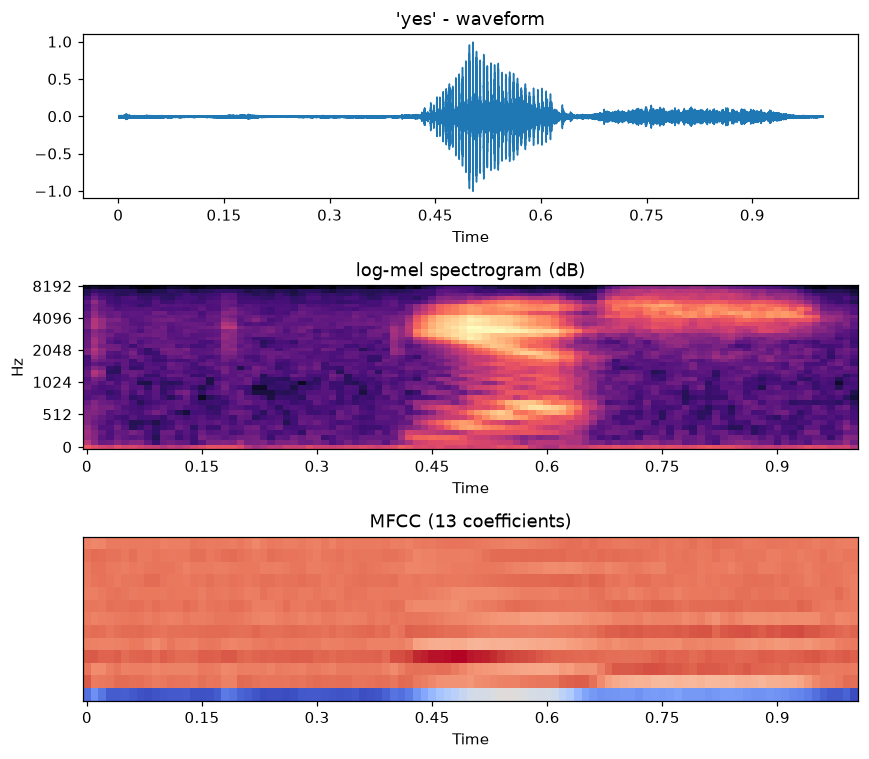

In [5]:
row = splits['train'][splits['train']['label'] == 'yes'].iloc[0]
y = preprocess(DATASET_DIR / row['path'])
fig, axes = plt.subplots(3, 1, figsize=(8, 7))
librosa.display.waveshow(y, sr=SR, ax=axes[0]); axes[0].set_title(f"'{row['label']}' - waveform")
librosa.display.specshow(log_mel(y), sr=SR, hop_length=HOP, x_axis='time', y_axis='mel', ax=axes[1]); axes[1].set_title('log-mel spectrogram (dB)')
mfcc = librosa.feature.mfcc(y=y, sr=SR, n_mfcc=13, n_fft=512, hop_length=HOP, n_mels=40)
librosa.display.specshow(mfcc, sr=SR, hop_length=HOP, x_axis='time', ax=axes[2]); axes[2].set_title('MFCC (13 coefficients)')
fig.tight_layout(); plt.show()

## 4. One example per word

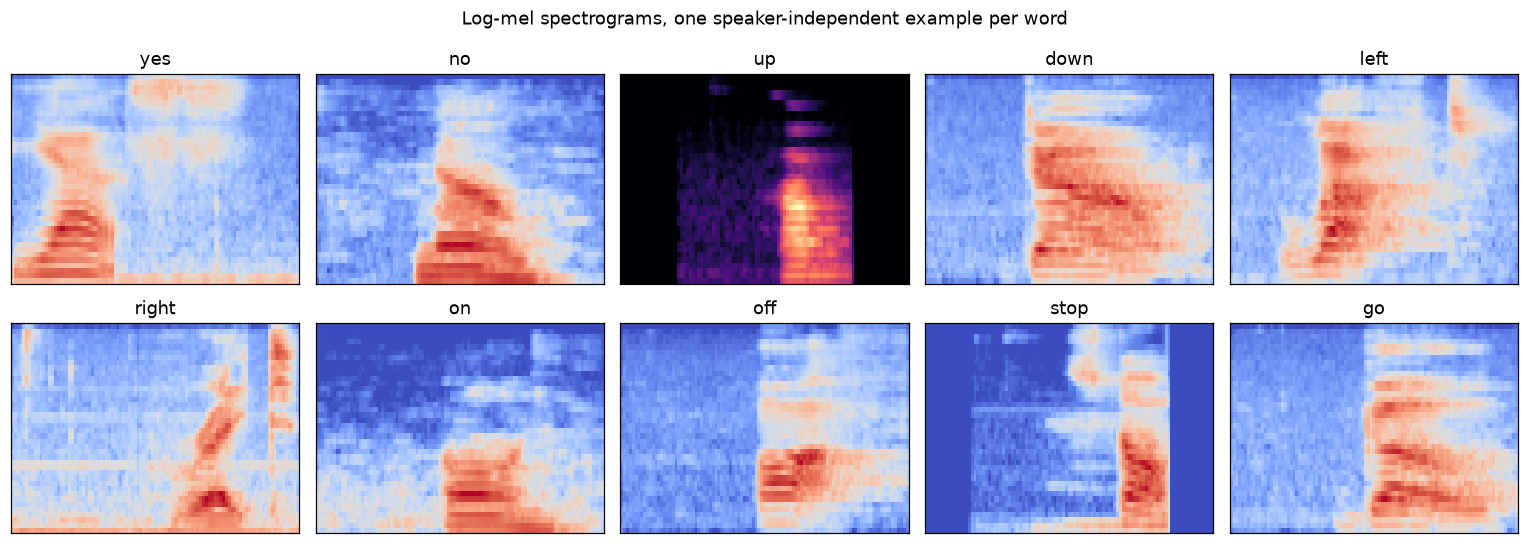

In [6]:
fig, axes = plt.subplots(2, 5, figsize=(14, 5))
for ax, w in zip(axes.ravel(), WORDS):
    p = splits['train'][splits['train']['label'] == w].iloc[3]['path']
    librosa.display.specshow(log_mel(preprocess(DATASET_DIR / p)), sr=SR, hop_length=HOP, ax=ax)
    ax.set_title(w)
fig.suptitle('Log-mel spectrograms, one speaker-independent example per word'); fig.tight_layout(); plt.show()

Words with very different vowels (`yes` vs `go`) look different. Short words with similar vowels (`on`/`off`, `no`/`go`, `down`/`no`) are expected to be the hardest pairs.

## 5. Background noises and SNR

SNR (signal-to-noise ratio) in dB = 10·log10(P_signal / P_noise). 20 dB: noise 100× weaker than speech; 0 dB: same power.

In [7]:
for f in sorted((DATASET_DIR / '_background_noise_').glob('*.wav')):
    info = sf.info(f); print(f'{f.name:28} {info.duration:6.1f} s')

doing_the_dishes.wav           95.2 s
dude_miaowing.wav              61.8 s
exercise_bike.wav              61.3 s
pink_noise.wav                 60.0 s
running_tap.wav                61.2 s
white_noise.wav                60.0 s


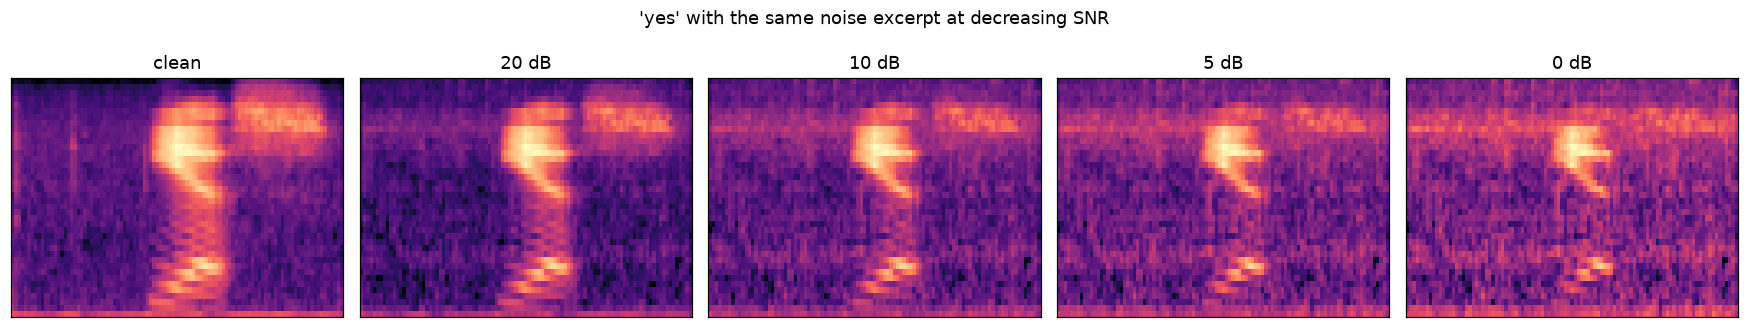

In [8]:
noises = load_background_noises('test')
fig, axes = plt.subplots(1, 5, figsize=(16, 3))
for ax, snr in zip(axes, [None, 20, 10, 5, 0]):
    z = y if snr is None else add_noise_snr(y, random_noise_segment(noises, np.random.default_rng(3)), snr)
    librosa.display.specshow(log_mel(z), sr=SR, hop_length=HOP, ax=ax)
    ax.set_title('clean' if snr is None else f'{snr} dB')
fig.suptitle("'yes' with the same noise excerpt at decreasing SNR"); fig.tight_layout(); plt.show()

As the SNR drops, the noise floor rises and the fine details disappear first (low-energy harmonics, the /s/ fricative); at 0 dB only the loudest vowel part stands out. This is where models trained on clean speech are expected to collapse, and where noise augmentation should help most.